In [42]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [43]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

1. 훈련데이터 , 테스트 데이터 분리
2. 훈련데이터 2차원 배열 변경
3. 데이터 학습
4. 데이터 예측
5. 정확도
6. 그래프

In [44]:
# 훈련, 테스트 데이터 분리
train_data, test_data, train_label, test_label= train_test_split(perch_length, perch_weight)

In [45]:
# 훈련/테스트 데이터는 2차원 데이터가 되어야함
# 훈련/ 테스트 데이터 2차원 배열 변경

train_data=train_data.reshape(-1,1)
test_data=test_data.reshape(-1,1)

In [46]:
# 데이터 학습
lr=LinearRegression()

# 선행회귀 : 
lr.fit(train_data,train_label)

# 데이터 예측
predict = lr.predict(test_data)
print('예측무게:',predict)

예측무게: [632.54213848 724.81606062 226.53688107  23.53425236 134.26295893
 964.72825818 244.9916655  171.17252779 208.08209664 171.17252779
 -42.90297158 374.17515649 171.17252779 798.63519833]


In [47]:
# 정확도
score= lr.score(train_data,train_label)
score2= lr.score(test_data,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.9091041809680729
test정확도 :  0.9533263312247908


In [48]:
print('기울기:',lr.coef_)
print('y절편:',lr.intercept_)

기울기: [36.90956886]
y절편: -640.8379870361058


In [49]:
in_data=input('농어의 길이를 입력하세요')
in_data=float(in_data)

result = lr.predict([[in_data]])
print(result)
print(f'농어 예측 무게: {result[0]:.2f}g')

[466.44907863]
농어 예측 무게: 466.45g


- 데이터가 곡선모양, 선행회귀로는 예측이 어려운 데이터
-> 다항회귀로 하는게 예측 정확도가 높아질 데이터

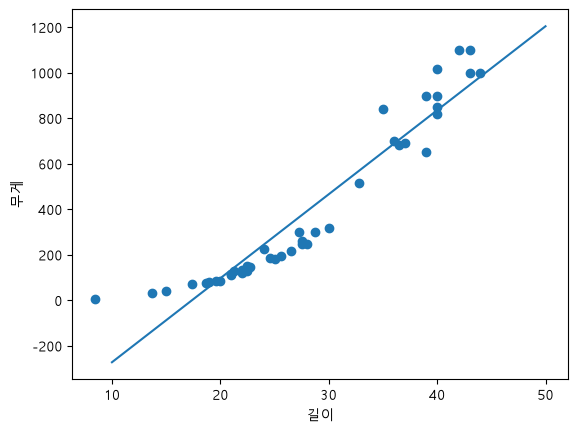

In [51]:
# 산점도 그래프

plt.scatter(train_data, train_label)
plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()
